# Text recognition

In [1]:
import os
import sys
import subprocess
import importlib.util

def ensure_package(import_name: str, pip_spec: str, no_deps: bool = False):
    if importlib.util.find_spec(import_name) is None:
        cmd = [sys.executable, "-m", "pip", "install", "-q"]
        if no_deps:
            cmd.append("--no-deps")
        cmd.append(pip_spec)
        subprocess.check_call(cmd)

ensure_package("shapely", "shapely>=2.0.0")
ensure_package("pyclipper", "pyclipper>=1.3.0")
ensure_package("gdown", "gdown>=5.1.0")
ensure_package("kagglehub", "kagglehub>=0.2.5")
ensure_package("huggingface_hub", "huggingface_hub>=0.23.0")
ensure_package("einops", "einops>=0.7.0", no_deps=True)
ensure_package("vietocr", "vietocr>=0.3.11", no_deps=True)

import json
import math
import glob
import re
import shutil
import random
import zipfile
import unicodedata
from pathlib import Path
from collections import Counter, defaultdict
from copy import deepcopy

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.models as tv_models
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from shapely.geometry import Polygon
from tqdm.auto import tqdm
import shapely

SEED = 20261108

def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

GPU_COUNT = torch.cuda.device_count() if torch.cuda.is_available() else 0
GPU_NAMES = [torch.cuda.get_device_name(i) for i in range(GPU_COUNT)]

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"TorchVision: {torchvision.__version__}")
print(f"OpenCV: {cv2.__version__}")
print(f"Shapely: {shapely.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Số lượng GPU đang kích hoạt: {GPU_COUNT}")
for idx, name in enumerate(GPU_NAMES):
    print(f"GPU {idx}: {name}")

Python: 3.13.16
NumPy: 2.4.6
PyTorch: 2.14.1+cu130
TorchVision: 0.29.1+cu130
OpenCV: 4.14.0
Shapely: 2.2.0
CUDA available: True
Số lượng GPU đang kích hoạt: 1
GPU 0: Tesla T4


In [2]:
# ============================================================
# CELL 2 — TẢI & THIẾT LẬP DỮ LIỆU THỰC TẾ ĐA NGUỒN
# ============================================================
WORK_DIR = Path("/kaggle/working/unified_ocr_project")
RAW_DATA_DIR = WORK_DIR / "raw_datasets"
UNIFIED_DET_DIR = WORK_DIR / "det_dataset"
UNIFIED_REC_DIR = WORK_DIR / "rec_dataset"
EXPORT_DIR = WORK_DIR / "exported_models"
KAGGLE_INPUT_DIR = Path("/kaggle/input")

VINTEXT_ROOT = RAW_DATA_DIR / "vintext_official"
ICDAR_ROOT = RAW_DATA_DIR / "icdar_vietnamese"
VIETOCR_ROOT = RAW_DATA_DIR / "vietocr_real_crops"

for folder in [WORK_DIR, RAW_DATA_DIR, UNIFIED_DET_DIR, UNIFIED_REC_DIR, EXPORT_DIR, ICDAR_ROOT, VIETOCR_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

import gdown

# 1. Tải VinText chính thức
VINTEXT_GOOGLE_DRIVE_ID = "1UUQhNvzgpZy7zXBFQp0Qox-BBjunZ0ml"

def has_vintext_gt(root: Path) -> bool:
    if not root.exists():
        return False
    try:
        return next(root.rglob("gt_*.txt"), None) is not None
    except (PermissionError, OSError):
        return False

def download_vintext():
    zip_path = RAW_DATA_DIR / "vietnamese_original.zip"
    if has_vintext_gt(VINTEXT_ROOT):
        print(f"[1/3] VinText đã có sẵn tại: {VINTEXT_ROOT}")
        return
    print("[1/3] Đang tải VinText (1.05 GB)...")
    try:
        result = gdown.download(id=VINTEXT_GOOGLE_DRIVE_ID, output=str(zip_path), quiet=False)
        if result and zip_path.exists() and zipfile.is_zipfile(zip_path):
            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(VINTEXT_ROOT)
            zip_path.unlink(missing_ok=True)
            print(f" -> Đã giải nén VinText vào: {VINTEXT_ROOT}")
    except Exception as e:
        print(f" -> Lỗi tải VinText: {e}")

# 2. Tải kho Crop từ ngữ tiếng Việt thực tế của VietOCR
# Link lưu trữ bộ từ vựng crop biển báo & tài liệu thực tế
VIETOCR_DRIVE_ID = "1m3f7g4C5k1U_s14J7FkF25jVq6P3LqG0"

def download_vietocr_crops():
    crop_txt = VIETOCR_ROOT / "labels.txt"
    if crop_txt.exists() and any(VIETOCR_ROOT.rglob("*.jpg")):
        print(f"[2/3] Dữ liệu VietOCR Crop thực tế đã sẵn sàng tại: {VIETOCR_ROOT}")
        return

    zip_path = RAW_DATA_DIR / "vietocr_data.zip"
    print("[2/3] Đang tải kho crop chữ tiếng Việt thực tế từ VietOCR Benchmark...")
    try:
        # Thử tải bộ crop chữ thực tế
        result = gdown.download(id=VIETOCR_DRIVE_ID, output=str(zip_path), quiet=True)
        if result and zip_path.exists() and zipfile.is_zipfile(zip_path):
            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(VIETOCR_ROOT)
            zip_path.unlink(missing_ok=True)
            print(f" -> Đã nạp thành công kho crop chữ VietOCR vào {VIETOCR_ROOT}")
        else:
            if zip_path.exists():
                zip_path.unlink()
            print(" -> Link drive phụ bị bận, tiếp tục với các nguồn thay thế...")
    except Exception as e:
        print(f" -> Bỏ qua VietOCR drive ({e}).")

# 3. Kéo tập ICDAR / Scene Text tiếng Việt từ kho raw GitHub của các nhóm nghiên cứu
def download_vietnamese_scene_text_icdar():
    target_dir = ICDAR_ROOT / "vietnamese_scene"
    if target_dir.exists() and any(target_dir.rglob("*.txt")):
        print(f"[3/3] Dữ liệu Scene Text bổ sung đã sẵn sàng tại: {ICDAR_ROOT}")
        return

    print("[3/3] Đang kéo tập nhãn & tọa độ Scene Text tiếng Việt mở rộng...")
    # Tải bộ chú thích ICDAR MLT Vietnamese mở rộng
    repo_url = "https://raw.githubusercontent.com/Fsoft-AIC/open-vietnamese-scene-text/main/annotations.zip"
    zip_path = RAW_DATA_DIR / "scene_text_extra.zip"
    try:
        subprocess.run(["wget", "-q", repo_url, "-O", str(zip_path)], check=False, timeout=60)
        if zip_path.exists() and zip_path.stat().st_size > 5000:
            target_dir.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zip_path, "r") as zf:
                zf.extractall(target_dir)
            zip_path.unlink(missing_ok=True)
            print(f" -> Đã giải nén dữ liệu mở rộng vào {target_dir}")
        else:
            if zip_path.exists():
                zip_path.unlink()
    except Exception:
        pass

download_vintext()
download_vietocr_crops()
download_vietnamese_scene_text_icdar()
print("Hoàn tất thiết lập tải dữ liệu.")

[1/3] Đang tải VinText (1.05 GB)...


Downloading...
From (original): https://drive.google.com/uc?id=1UUQhNvzgpZy7zXBFQp0Qox-BBjunZ0ml
From (redirected): https://drive.google.com/uc?id=1UUQhNvzgpZy7zXBFQp0Qox-BBjunZ0ml&confirm=t&uuid=77fe30fa-de11-4a72-9eeb-f54e450c9ecf
To: /kaggle/working/unified_ocr_project/raw_datasets/vietnamese_original.zip
100%|██████████| 1.05G/1.05G [00:13<00:00, 79.0MB/s]


 -> Đã giải nén VinText vào: /kaggle/working/unified_ocr_project/raw_datasets/vintext_official
[2/3] Đang tải kho crop chữ tiếng Việt thực tế từ VietOCR Benchmark...
 -> Bỏ qua VietOCR drive (Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1m3f7g4C5k1U_s14J7FkF25jVq6P3LqG0

but Gdown can't. Please check connections and permissions.).
[3/3] Đang kéo tập nhãn & tọa độ Scene Text tiếng Việt mở rộng...
Hoàn tất thiết lập tải dữ liệu.


In [3]:
# ============================================================
# CELL 3 — BỘ TỪ VỰNG TIẾNG VIỆT 233 LỚP KÝ TỰ & GIẢI MÃ NFC
# ============================================================
IMAGENET_MEAN = np.asarray([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.asarray([0.229, 0.224, 0.225], dtype=np.float32)

MAX_LABEL_LENGTH = 25

VIETOCR_CHARS = (
    "aAàÀảẢãÃáÁạẠăĂằẰẳẲẵẴắẮặẶâÂầẦẩẨẫẪấẤậẬbBcCdDđĐeEèÈẻẺẽẼéÉẹẸêÊềỀểỂễỄếẾệỆ"
    "fFgGhHiIìÌỉỈĩĨíÍịỊjJkKlLmMnNoOòÒỏỎõÕóÓọỌôÔồỒổỔỗỖốỐộỘơƠờỜởỞỡỠớỚợỢpPqQrRsStT"
    "uUùÙủỦũŨúÚụỤưƯừỪửỬữỮứỨựỰvVwWxXyYỳỲỷỶỹỸýÝỵỴzZ0123456789"
    "!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~ "
)

VOCAB_RAW = list(" !\"#$%&'()*+,-./0123456789:;<=>?@ABCDEFGHIJKLMNOPQRSTUVWXYZ[\\]^_`abcdefghijklmnopqrstuvwxyz{|}~")
PAD_IDS = {96, 108}

ACCENT_MAP = {
    95: {"d": "đ", "D": "Đ"},
    100: {"a": "ă", "A": "Ă"},
    101: {"a": "â", "A": "Â", "e": "ê", "E": "Ê", "o": "ô", "O": "Ô"},
    102: {"o": "ơ", "O": "Ơ", "u": "ư", "U": "Ư"},
}

TONE_MAP = {
    103: {
        "a": "à", "ă": "ằ", "â": "ầ", "e": "è", "ê": "ề", "i": "ì", "o": "ò", "ô": "ồ",
        "ơ": "ờ", "u": "ù", "ư": "ừ", "y": "ỳ", "A": "À", "Ă": "Ằ", "Â": "Ầ", "E": "È",
        "Ê": "Ề", "I": "Ì", "O": "Ò", "Ô": "Ồ", "Ơ": "Ờ", "U": "Ù", "Ư": "Ừ", "Y": "Ỳ",
    },
    104: {
        "a": "ả", "ă": "ẳ", "â": "ẩ", "e": "ẻ", "ê": "ể", "i": "ỉ", "o": "ỏ", "ô": "ổ",
        "ơ": "ở", "u": "ủ", "ư": "ử", "y": "ỷ", "A": "Ả", "Ă": "Ẳ", "Â": "Ẩ", "E": "Ẻ",
        "Ê": "Ể", "I": "Ỉ", "O": "Ỏ", "Ô": "Ổ", "Ơ": "Ở", "U": "Ủ", "Ư": "Ử", "Y": "Ỷ",
    },
    105: {
        "a": "ã", "ă": "ẵ", "â": "ẫ", "e": "ẽ", "ê": "ễ", "i": "ĩ", "o": "õ", "ô": "ỗ",
        "ơ": "ỡ", "u": "ũ", "ư": "ữ", "y": "ỹ", "A": "Ã", "Ă": "Ẵ", "Â": "Ẫ", "E": "Ẽ",
        "Ê": "Ễ", "I": "Ĩ", "O": "Õ", "Ô": "Ỗ", "Ơ": "Ỡ", "U": "Ũ", "Ư": "Ữ", "Y": "Ỹ",
    },
    106: {
        "a": "á", "ă": "ắ", "â": "ấ", "e": "é", "ê": "ế", "i": "í", "o": "ó", "ô": "ố",
        "ơ": "ớ", "u": "ú", "ư": "ứ", "y": "ý", "A": "Á", "Ă": "Ắ", "Â": "Ấ", "E": "É",
        "Ê": "Ế", "I": "Í", "O": "Ó", "Ô": "Ố", "Ơ": "Ớ", "U": "Ú", "Ư": "Ứ", "Y": "Ý",
    },
    107: {
        "a": "ạ", "ă": "ặ", "â": "ậ", "e": "ẹ", "ê": "ệ", "i": "ị", "o": "ọ", "ô": "ộ",
        "ơ": "ợ", "u": "ụ", "ư": "ự", "y": "ỵ", "A": "Ạ", "Ă": "Ặ", "Â": "Ậ", "E": "Ẹ",
        "Ê": "Ệ", "I": "Ị", "O": "Ọ", "Ô": "Ộ", "Ơ": "Ợ", "U": "Ụ", "Ư": "Ự", "Y": "Ỵ",
    },
}

def normalize_nfc(text: str) -> str:
    text = unicodedata.normalize("NFC", str(text))
    text = text.replace("\ufeff", "").replace("\u200b", "").replace("\t", " ").replace("\n", " ").replace("\r", " ")
    return " ".join(text.split()).strip()

def clean_and_decode_rec(raw_rec) -> str:
    sequence = [int(v) for v in raw_rec]
    while sequence and sequence[-1] in PAD_IDS:
        sequence.pop()
    chars = []
    for token_id in sequence:
        if token_id in PAD_IDS or token_id < 0:
            continue
        if 0 <= token_id < len(VOCAB_RAW):
            chars.append(VOCAB_RAW[token_id])
        elif token_id in ACCENT_MAP and chars:
            chars[-1] = ACCENT_MAP[token_id].get(chars[-1], chars[-1])
        elif token_id in TONE_MAP and chars:
            chars[-1] = TONE_MAP[token_id].get(chars[-1], chars[-1])
    return normalize_nfc("".join(chars))

class VietnameseVocab:
    def __init__(self, characters=None):
        self.PAD, self.SOS, self.EOS, self.UNK = "<pad>", "<sos>", "<eos>", "<unk>"
        self.special_tokens = [self.PAD, self.SOS, self.EOS, self.UNK]
        self.char2idx = {token: idx for idx, token in enumerate(self.special_tokens)}
        self.idx2char = {idx: token for token, idx in self.char2idx.items()}
        for ch in (VIETOCR_CHARS if characters is None else characters):
            if ch not in self.char2idx:
                idx = len(self.char2idx)
                self.char2idx[ch] = idx
                self.idx2char[idx] = ch

    def encode(self, text: str) -> list[int]:
        norm = normalize_nfc(text)
        return [
            self.char2idx[self.SOS],
            *(self.char2idx.get(ch, self.char2idx[self.UNK]) for ch in norm),
            self.char2idx[self.EOS],
        ]

    def decode(self, indices) -> str:
        chars = []
        for val in indices:
            idx = int(val)
            if idx in (self.char2idx[self.PAD], self.char2idx[self.EOS]):
                break
            if idx in (self.char2idx[self.SOS], self.char2idx[self.UNK]):
                continue
            chars.append(self.idx2char.get(idx, ""))
        return normalize_nfc("".join(chars))

    def to_json(self) -> dict:
        return {
            "special_tokens": self.special_tokens,
            "characters": [self.idx2char[idx] for idx in range(4, len(self))],
        }

    def __len__(self) -> int:
        return len(self.char2idx)

VOCAB = VietnameseVocab()
(EXPORT_DIR / "vocab.json").write_text(json.dumps(VOCAB.to_json(), ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Đã khởi tạo bộ từ vựng với {len(VOCAB)} lớp ký tự.")

Đã khởi tạo bộ từ vựng với 233 lớp ký tự.


In [4]:
# ============================================================
# CELL 4 — ĐỌC DỮ LIỆU VÀ TẠO TẬP RECOGNITION
# ============================================================

def order_points_clockwise(points: np.ndarray) -> np.ndarray:
    """Sắp xếp 4 đỉnh theo thứ tự trái-trên, phải-trên, phải-dưới, trái-dưới."""
    points = np.asarray(points, dtype=np.float32).reshape(4, 2)
    center = points.mean(axis=0)
    angles = np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0])
    ordered = points[np.argsort(angles)]

    if cv2.contourArea(ordered.reshape(-1, 1, 2), oriented=True) < 0:
        ordered = ordered[::-1]

    start = int(np.argmin(ordered.sum(axis=1)))
    return np.roll(ordered, -start, axis=0).astype(np.float32)


def poly_to_quad(coords) -> np.ndarray | None:
    points = np.asarray(coords, dtype=np.float32).reshape(-1, 2)
    if len(points) < 4 or not np.isfinite(points).all():
        return None

    if len(points) == 4:
        quad = order_points_clockwise(points)
    else:
        quad = order_points_clockwise(cv2.boxPoints(cv2.minAreaRect(points)))

    contour = quad.reshape(-1, 1, 2)
    if not cv2.isContourConvex(contour) or abs(cv2.contourArea(contour)) < 16:
        return None
    return quad


def crop_and_rectify(
    image: np.ndarray,
    polygon_points: np.ndarray,
    pad_ratio: float = 0.05,
) -> np.ndarray | None:
    """Cắt theo tứ giác gốc, giữ phối cảnh thay vì ép về minAreaRect."""
    if image is None or image.ndim != 3:
        return None

    quad = poly_to_quad(polygon_points)
    if quad is None:
        return None

    center = quad.mean(axis=0)
    quad = quad + (quad - center) * max(0.0, float(pad_ratio))

    width = int(round(max(
        np.linalg.norm(quad[1] - quad[0]),
        np.linalg.norm(quad[2] - quad[3]),
    )))
    height = int(round(max(
        np.linalg.norm(quad[3] - quad[0]),
        np.linalg.norm(quad[2] - quad[1]),
    )))
    if width < 6 or height < 6:
        return None

    destination = np.array(
        [[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]],
        dtype=np.float32,
    )
    matrix = cv2.getPerspectiveTransform(quad, destination)
    crop = cv2.warpPerspective(
        image,
        matrix,
        (width, height),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE,
    )

    if crop.shape[0] > crop.shape[1] * 1.5:
        crop = cv2.rotate(crop, cv2.ROTATE_90_COUNTERCLOCKWISE)
    return crop


def _vintext_numeric_id(name: str) -> str:
    stem = Path(str(name)).stem.lower()
    match = re.search(r"(\d+)$", stem)
    if match:
        return str(int(match.group(1)))

    for prefix in ("gt_", "gt-", "image_", "img_", "im_", "img", "im"):
        if stem.startswith(prefix):
            return stem[len(prefix):].lstrip("_- ")
    return stem


def discover_vintext_layouts(search_roots: list[Path]) -> list[dict]:
    layouts = []
    seen = set()
    label_names = {"labels", "label", "gt", "annotations"}

    for search_root in search_roots:
        if not search_root.exists():
            continue

        for train_dir in search_root.rglob("train_images"):
            if not train_dir.is_dir():
                continue

            parent = train_dir.parent
            label_dir = next(
                (p for p in parent.iterdir() if p.is_dir() and p.name.lower() in label_names),
                None,
            )
            if label_dir is None:
                continue

            split_dirs = {
                "train_images": train_dir,
                "val_images": next(
                    (p for p in parent.iterdir() if p.is_dir() and p.name.lower() in {"val_image", "val_images"}),
                    None,
                ),
                "test_images": next(
                    (p for p in parent.iterdir() if p.is_dir() and p.name.lower() in {"test_image", "test_images"}),
                    None,
                ),
            }

            key = str(parent.resolve())
            if key not in seen:
                seen.add(key)
                layouts.append({"root": parent, "labels": label_dir, **split_dirs})

    return layouts


def _valid_recognition_text(text: str) -> bool:
    return (
        bool(text)
        and text != "###"
        and len(text) <= MAX_LABEL_LENGTH
        and all(char in VOCAB.char2idx for char in text)
    )


def parse_all_datasets():
    search_roots = [KAGGLE_INPUT_DIR, RAW_DATA_DIR]
    all_det, all_rec = [], []
    skipped_long_labels = 0

    # 1. VinText: giữ riêng train, validation và test nếu có đủ thư mục.
    for layout in discover_vintext_layouts(search_roots):
        label_dir = layout["labels"]
        label_map = {
            _vintext_numeric_id(path.stem): path
            for path in label_dir.rglob("gt_*.txt")
        }

        split_dirs = [
            (layout["train_images"], "train"),
            (layout["val_images"], "val"),
            (layout["test_images"], "test"),
        ]

        for image_dir, split_tag in split_dirs:
            if image_dir is None or not image_dir.is_dir():
                continue

            for image_path in sorted(image_dir.rglob("*")):
                if not image_path.is_file() or image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                    continue

                label_path = label_map.get(_vintext_numeric_id(image_path.stem))
                if label_path is None:
                    continue

                annotations = []
                lines = label_path.read_text(encoding="utf-8-sig", errors="ignore").splitlines()
                for line in lines:
                    parts = line.strip().split(",", 8)
                    if len(parts) < 9:
                        continue

                    try:
                        coords = [float(value.strip()) for value in parts[:8]]
                        text = normalize_nfc(parts[8])
                        quad = poly_to_quad(coords)
                    except (TypeError, ValueError):
                        continue

                    if quad is None:
                        continue
                    if not text:
                        text = "###"

                    annotations.append({
                        "transcription": text,
                        "points": np.round(quad, 2).tolist(),
                    })

                    if text == "###":
                        continue
                    if len(text) > MAX_LABEL_LENGTH:
                        skipped_long_labels += 1
                        continue
                    if not _valid_recognition_text(text):
                        continue

                    all_rec.append({
                        "source_image": str(image_path.resolve()),
                        "polygon": np.round(quad, 2).tolist(),
                        "text": text,
                        "split": split_tag,
                        "domain": "real",
                    })

                if annotations:
                    all_det.append({
                        "image_path": str(image_path.resolve()),
                        "annotations": annotations,
                        "split": split_tag,
                        "domain": "real",
                    })

    # 2. Crop/TSV data. Never mix a named validation or test file into train.
    for txt_path in RAW_DATA_DIR.rglob("*.txt"):
        if txt_path.name.startswith("gt_"):
            continue
        try:
            lines = txt_path.read_text(encoding="utf-8-sig", errors="ignore").splitlines()
        except OSError:
            continue

        if not lines or "\t" not in lines[0]:
            continue

        file_name = txt_path.stem.lower()
        if "val" in file_name:
            split_tag = "val"
        elif "test" in file_name:
            split_tag = "test"
        else:
            split_tag = "train"

        is_synth = "synth" in str(txt_path).lower()
        parent = txt_path.parent

        for line in lines:
            if "\t" not in line:
                continue

            relative_path, annotation = line.split("\t", 1)
            target_path = (parent / relative_path).resolve()
            if not target_path.is_file():
                target_path = (parent.parent / relative_path).resolve()
            if not target_path.is_file():
                continue

            if annotation.strip().startswith("["):
                try:
                    polygon_annotations = json.loads(annotation)
                except json.JSONDecodeError:
                    continue

                valid_annotations = []
                for item in polygon_annotations:
                    quad = poly_to_quad(item.get("points", []))
                    if quad is None:
                        continue
                    valid_annotations.append({
                        "transcription": item.get("transcription", "###"),
                        "points": np.round(quad, 2).tolist(),
                    })

                if valid_annotations:
                    all_det.append({
                        "image_path": str(target_path),
                        "annotations": valid_annotations,
                        "split": split_tag,
                        "domain": "synth" if is_synth else "real",
                    })
                continue

            text = normalize_nfc(annotation)
            if len(text) > MAX_LABEL_LENGTH:
                skipped_long_labels += 1
                continue
            if _valid_recognition_text(text):
                all_rec.append({
                    "crop_path": str(target_path),
                    "text": text,
                    "split": split_tag,
                    "domain": "synth" if is_synth else "real",
                })

    # Remove repeated detection images and repeated recognition samples.
    unique_det = {}
    for item in all_det:
        key = (item["image_path"], item["split"])
        unique_det[key] = item

    unique_rec = {}
    for item in all_rec:
        source = item.get("source_image") or item.get("crop_path") or ""
        polygon = np.asarray(item.get("polygon", []), dtype=np.float32).reshape(-1).round(2)
        key = (source, tuple(polygon.tolist()), item["text"], item["split"])
        unique_rec[key] = item

    det_items = list(unique_det.values())
    rec_items = list(unique_rec.values())

    det_train = [item for item in det_items if item["split"] == "train"]
    det_val = [item for item in det_items if item["split"] == "val"]
    det_test = [item for item in det_items if item["split"] == "test"]

    if not det_val and len(det_train) > 20:
        rng = random.Random(SEED)
        rng.shuffle(det_train)
        val_count = max(1, int(len(det_train) * 0.1))
        det_val, det_train = det_train[:val_count], det_train[val_count:]

    print("\n========== TỔNG KẾT DỮ LIỆU ==========")
    print(f"Detection train: {len(det_train):,}")
    print(f"Detection val:   {len(det_val):,}")
    print(f"Detection test:  {len(det_test):,}")
    print(f"Recognition:     {len(rec_items):,}")
    print(f"Nhãn quá {MAX_LABEL_LENGTH} ký tự đã bỏ: {skipped_long_labels:,}")
    print("====================================\n")

    return det_train, det_val, rec_items, det_test


def _recognition_group_key(item: dict) -> str:
    """Các từ cùng một ảnh gốc phải nằm chung một split."""
    source = item.get("source_image") or item.get("crop_path")
    return str(Path(source).resolve()) if source else ""


def split_recognition_items(
    items: list[dict],
    val_ratio: float = 0.1,
    seed: int = SEED,
):
    train_items = [item for item in items if item.get("split") == "train"]
    val_items = [item for item in items if item.get("split") == "val"]
    test_items = [item for item in items if item.get("split") == "test"]

    # A source image must never appear in more than one split.
    test_groups = {_recognition_group_key(item) for item in test_items}
    train_items = [item for item in train_items if _recognition_group_key(item) not in test_groups]
    val_items = [item for item in val_items if _recognition_group_key(item) not in test_groups]

    # Use an explicit validation split when available. Otherwise split by source image.
    if not val_items and len(train_items) > 1:
        groups = sorted({_recognition_group_key(item) for item in train_items})
        groups = [group for group in groups if group]
        if len(groups) < 2:
            raise ValueError("Không đủ ảnh nguồn để tách Recognition train/validation.")

        rng = random.Random(seed)
        rng.shuffle(groups)
        val_count = min(len(groups) - 1, max(1, round(len(groups) * val_ratio)))
        val_groups = set(groups[:val_count])
        val_items = [item for item in train_items if _recognition_group_key(item) in val_groups]
        train_items = [item for item in train_items if _recognition_group_key(item) not in val_groups]

    # Keep train and validation source images disjoint, including mixed-source datasets.
    val_groups = {_recognition_group_key(item) for item in val_items}
    train_items = [
        item for item in train_items
        if _recognition_group_key(item) not in val_groups | test_groups
    ]

    if not train_items:
        raise ValueError("Recognition train đang rỗng sau khi chia dữ liệu.")
    if not val_items:
        raise ValueError("Recognition validation đang rỗng. Cần ít nhất 2 ảnh nguồn.")

    return train_items, val_items, test_items


DET_TRAIN_ITEMS, DET_VAL_ITEMS, RAW_REC_ITEMS, DET_TEST_ITEMS = parse_all_datasets()
REC_TRAIN_ITEMS, REC_VAL_ITEMS, REC_TEST_ITEMS = split_recognition_items(RAW_REC_ITEMS)

print(f"Recognition train: {len(REC_TRAIN_ITEMS):,}")
print(f"Recognition val:   {len(REC_VAL_ITEMS):,}")
print(f"Recognition test:  {len(REC_TEST_ITEMS):,}")



========== TỔNG KẾT DỮ LIỆU ==========
Detection train: 1,080
Detection val:   120
Detection test:  300
Recognition:     32,889
Nhãn quá 25 ký tự đã bỏ: 3

Recognition train: 23,252
Recognition val:   2,446
Recognition test:  7,191


In [5]:
ensure_package("timm", "timm>=0.9.12")
ensure_package("lightning", "lightning>=2.2.0")
ensure_package("omegaconf", "omegaconf>=2.3.0")

from PIL import Image

def apply_motion_blur_crop(img: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    ksize = int(rng.choice([3, 5, 7]))
    kernel = np.zeros((ksize, ksize), dtype=np.float32)
    angle = float(rng.uniform(0, 180))
    c, s = math.cos(math.radians(angle)), math.sin(math.radians(angle))
    center = ksize // 2
    for i in range(ksize):
        offset = i - center
        x = int(round(center + offset * c))
        y = int(round(center + offset * s))
        if 0 <= x < ksize and 0 <= y < ksize:
            kernel[y, x] = 1.0
    kernel /= max(1.0, float(kernel.sum()))
    return cv2.filter2D(img, -1, kernel)

def apply_hard_crop_augmentation(crop_rgb: np.ndarray, rng: np.random.Generator, intensity: str = "hard") -> np.ndarray:
    out = crop_rgb.copy()
    h, w = out.shape[:2]
    if h < 8 or w < 8:
        return out

    p_scale = 1.0 if intensity == "hard" else 0.35

    if rng.random() < 0.65 * p_scale:
        src = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)
        dx = w * 0.06
        dy = h * 0.08
        dst = src + rng.uniform(
            [[-dx, -dy], [-dx, -dy], [-dx, -dy], [-dx, -dy]],
            [[dx, dy], [dx, dy], [dx, dy], [dx, dy]],
        ).astype(np.float32)
        matrix = cv2.getPerspectiveTransform(src, dst)
        out = cv2.warpPerspective(out, matrix, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

    if rng.random() < 0.25 * p_scale:
        x1, y1 = int(rng.integers(0, w)), int(rng.integers(0, h))
        x2, y2 = int(rng.integers(0, w)), int(rng.integers(0, h))
        color = tuple(int(c) for c in rng.integers(10, 120, size=3))
        thickness = 1 if h < 28 else int(rng.integers(1, 3))
        cv2.line(out, (x1, y1), (x2, y2), color, thickness, cv2.LINE_AA)

    if rng.random() < 0.45 * p_scale:
        yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
        nx, ny = float(rng.uniform(-1, 1)), float(rng.uniform(-1, 1))
        thresh = float(rng.uniform(0.25, 0.75)) * (w * abs(nx) + h * abs(ny))
        dist = xx * nx + yy * ny
        mask = 1.0 / (1.0 + np.exp(-(dist - thresh) / max(3.0, h * 0.15)))
        factor = float(rng.uniform(0.45, 0.78)) if rng.random() < 0.55 else float(rng.uniform(1.20, 1.50))
        out = np.clip(out.astype(np.float32) * (1.0 + (factor - 1.0) * mask[:, :, None]), 0, 255).astype(np.uint8)

    if rng.random() < 0.70 * p_scale:
        alpha = float(rng.uniform(0.68, 1.35))
        beta = float(rng.uniform(-28, 28))
        out = np.clip(out.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)

    if rng.random() < 0.30 * p_scale:
        gamma = float(rng.uniform(0.65, 1.45))
        lut = np.array([((i / 255.0) ** gamma) * 255 for i in range(256)]).clip(0, 255).astype(np.uint8)
        out = cv2.LUT(out, lut)

    if rng.random() < 0.35 * p_scale:
        if rng.random() < 0.6:
            out = apply_motion_blur_crop(out, rng)
        else:
            k = int(rng.choice([3, 5]))
            out = cv2.GaussianBlur(out, (k, k), sigmaX=float(rng.uniform(0.4, 1.4)))

    if rng.random() < 0.25 * p_scale:
        scale = float(rng.uniform(0.40, 0.70))
        sw, sh = max(6, int(w * scale)), max(6, int(h * scale))
        out = cv2.resize(cv2.resize(out, (sw, sh), interpolation=cv2.INTER_AREA), (w, h), interpolation=cv2.INTER_LINEAR)

    if rng.random() < 0.30 * p_scale and w > 20:
        num_holes = int(rng.integers(1, 3))
        for _ in range(num_holes):
            hole_w = max(2, int(rng.uniform(0.03, 0.08) * w))
            hole_h = max(2, int(rng.uniform(0.10, 0.25) * h))
            x0 = int(rng.integers(0, max(1, w - hole_w)))
            y0 = int(rng.integers(0, max(1, h - hole_h)))
            fill_val = int(np.median(out))
            out[y0 : y0 + hole_h, x0 : x0 + hole_w] = fill_val

    if rng.random() < 0.35 * p_scale:
        sigma = float(rng.uniform(3.0, 12.0))
        noise = rng.normal(0, sigma, out.shape).astype(np.float32)
        out = np.clip(out.astype(np.float32) + noise, 0, 255).astype(np.uint8)

    return out

def fallback_rectify_quad(image_bgr: np.ndarray, pts: np.ndarray) -> np.ndarray:
    pts = pts.astype(np.float32).reshape(4, 2)
    w_top = np.linalg.norm(pts[1] - pts[0])
    w_bot = np.linalg.norm(pts[2] - pts[3])
    max_w = max(int(round(max(w_top, w_bot))), 8)
    h_left = np.linalg.norm(pts[3] - pts[0])
    h_right = np.linalg.norm(pts[2] - pts[1])
    max_h = max(int(round(max(h_left, h_right))), 8)
    dst = np.array([[0, 0], [max_w - 1, 0], [max_w - 1, max_h - 1], [0, max_h - 1]], dtype=np.float32)
    matrix = cv2.getPerspectiveTransform(pts, dst)
    warped = cv2.warpPerspective(image_bgr, matrix, (max_w, max_h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
    if warped.shape[0] > warped.shape[1] * 1.5 and warped.shape[0] > 32:
        warped = cv2.rotate(warped, cv2.ROTATE_90_COUNTERCLOCKWISE)
    return warped

def robust_crop_text_region(image_bgr: np.ndarray, polygon) -> np.ndarray | None:
    """Cắt vùng chữ với nhiều lớp dự phòng để không bao giờ làm sập DataLoader.

    Nguyên nhân lỗi cũ: bước lọc ở cell 4 (poly_to_quad) chỉ yêu cầu diện tích >= 16 px²,
    nhưng crop_and_rectify trả None khi bất kỳ cạnh nào < 6 px. VinText có nhiều chữ rất nhỏ
    nên các mẫu này lọt qua bước lọc rồi bị từ chối lúc huấn luyện.

    Thứ tự thử:
      1) crop_and_rectify (đường chính, có pad 5%)
      2) fallback_rectify_quad (ép kích thước tối thiểu 8 px, giữ phối cảnh)
      3) bounding box thẳng, kẹp trong biên ảnh
    """
    pts = np.asarray(polygon, dtype=np.float32).reshape(-1, 2)
    if len(pts) < 3 or not np.isfinite(pts).all():
        return None

    crop = crop_and_rectify(image_bgr, pts)
    if crop is not None and crop.size > 0:
        return crop

    quad = poly_to_quad(pts)
    if quad is not None:
        side_w = min(np.linalg.norm(quad[1] - quad[0]), np.linalg.norm(quad[2] - quad[3]))
        side_h = min(np.linalg.norm(quad[3] - quad[0]), np.linalg.norm(quad[2] - quad[1]))
        if min(side_w, side_h) >= 2.0:  # mỏng hơn 2 px thì không còn nội dung để đọc
            try:
                crop = fallback_rectify_quad(image_bgr, quad)
            except cv2.error:
                crop = None
            if crop is not None and crop.size > 0:
                return crop

    img_h, img_w = image_bgr.shape[:2]
    x1 = max(int(np.floor(pts[:, 0].min())), 0)
    y1 = max(int(np.floor(pts[:, 1].min())), 0)
    x2 = min(int(np.ceil(pts[:, 0].max())), img_w)
    y2 = min(int(np.ceil(pts[:, 1].max())), img_h)
    if x2 - x1 >= 2 and y2 - y1 >= 2:
        return image_bgr[y1:y2, x1:x2].copy()
    return None

if "ModelEMA" not in globals():
    class ModelEMA:
        def __init__(self, model: nn.Module, decay: float = 0.998):
            base = model.module if isinstance(model, nn.DataParallel) else model
            self.ema = deepcopy(base).eval()
            self.decay = decay
            for p in self.ema.parameters():
                p.requires_grad_(False)

        @torch.no_grad()
        def update(self, model: nn.Module):
            base = model.module if isinstance(model, nn.DataParallel) else model
            msd = base.state_dict()
            for k, ema_v in self.ema.state_dict().items():
                model_v = msd[k].detach()
                if ema_v.dtype.is_floating_point:
                    ema_v.mul_(self.decay).add_(model_v, alpha=1.0 - self.decay)
                else:
                    ema_v.copy_(model_v)

class ParseqRecognitionDataset(Dataset):
    def __init__(self, items: list[dict], is_train: bool = True, aug_prob: float = 0.7):
        self.items = items
        self.is_train = is_train
        self.aug_prob = aug_prob
        self._rng = None
        self._warned_bad = set()  # mỗi worker tự nhớ mẫu lỗi đã in cảnh báo
        self.to_tensor = torchvision.transforms.Compose([
            torchvision.transforms.Resize(
                (32, 128),
                interpolation=torchvision.transforms.InterpolationMode.BICUBIC,
            ),
            torchvision.transforms.ToTensor(),
            torchvision.transforms.Normalize(
                mean=[0.5, 0.5, 0.5],
                std=[0.5, 0.5, 0.5],
            ),
        ])

        for index, item in enumerate(self.items):
            text = normalize_nfc(item.get("text") or item.get("label", ""))
            if not text:
                raise ValueError(f"Mẫu {index} có nhãn rỗng.")
            if len(text) > MAX_LABEL_LENGTH:
                raise ValueError(
                    f"Mẫu {index} có {len(text)} ký tự, vượt MAX_LABEL_LENGTH={MAX_LABEL_LENGTH}: {text!r}"
                )
            if not all(char in VOCAB.char2idx for char in text):
                raise ValueError(f"Mẫu {index} chứa ký tự ngoài vocabulary: {text!r}")

    def _get_rng(self):
        if self._rng is None:
            worker_info = torch.utils.data.get_worker_info()
            worker_seed = SEED if worker_info is None else worker_info.seed
            self._rng = np.random.default_rng(worker_seed)
        return self._rng

    def __len__(self) -> int:
        return len(self.items)

    def _load_crop(self, item: dict, index: int) -> np.ndarray:
        crop_path = item.get("crop_path")
        if crop_path:
            image_path = Path(crop_path)
            if not image_path.is_file():
                raise FileNotFoundError(f"Không tìm thấy crop ở mẫu {index}: {image_path}")
            image_bgr = cv2.imread(str(image_path))
            if image_bgr is None:
                raise RuntimeError(f"OpenCV không đọc được crop ở mẫu {index}: {image_path}")
            return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

        source_path = item.get("source_image") or item.get("image_path") or item.get("path")
        if not source_path:
            raise ValueError(f"Mẫu {index} không có crop_path hoặc source_image.")

        image_path = Path(source_path)
        if not image_path.is_file():
            raise FileNotFoundError(f"Không tìm thấy ảnh nguồn ở mẫu {index}: {image_path}")

        image_bgr = cv2.imread(str(image_path))
        if image_bgr is None:
            raise RuntimeError(f"OpenCV không đọc được ảnh nguồn ở mẫu {index}: {image_path}")

        polygon = next(
            (item[key] for key in ("polygon", "poly", "pts", "points", "quad")
             if item.get(key) is not None),
            None,
        )
        if polygon is None:
            raise ValueError(f"Mẫu {index} thiếu polygon để cắt từ ảnh nguồn: {image_path}")

        crop_bgr = robust_crop_text_region(image_bgr, polygon)
        if crop_bgr is None or crop_bgr.size == 0:
            raise RuntimeError(f"Không thể crop vùng chữ ở mẫu {index}: {image_path}")

        return cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)

    def __getitem__(self, idx: int):
        max_attempts = 8
        last_error = None

        for attempt in range(max_attempts):
            real_idx = (idx + attempt) % len(self.items)
            item = self.items[real_idx]
            try:
                crop_rgb = self._load_crop(item, real_idx)
            except (RuntimeError, ValueError, OSError, cv2.error) as exc:
                # Một mẫu hỏng (ảnh lỗi, vùng chữ suy biến...) không được làm sập cả quá trình train.
                last_error = exc
                if real_idx not in self._warned_bad:
                    self._warned_bad.add(real_idx)
                    print(f"[Cảnh báo] Bỏ qua mẫu lỗi #{real_idx}: {exc}")
                continue

            if self.is_train and self._get_rng().random() < self.aug_prob:
                crop_rgb = apply_hard_crop_augmentation(
                    crop_rgb,
                    self._get_rng(),
                    intensity="medium",
                )

            image = self.to_tensor(Image.fromarray(crop_rgb))
            label = normalize_nfc(item.get("text") or item.get("label", ""))
            return image, label

        raise RuntimeError(
            f"{max_attempts} mẫu liên tiếp từ #{idx} đều không đọc được. "
            f"Lỗi cuối: {last_error}. Hãy kiểm tra lại đường dẫn dữ liệu."
        )

def compute_levenshtein(s1: str, s2: str) -> int:
    if len(s1) < len(s2):
        return compute_levenshtein(s2, s1)
    if len(s2) == 0:
        return len(s1)
    prev_row = list(range(len(s2) + 1))
    for i, c1 in enumerate(s1):
        curr_row = [i + 1]
        for j, c2 in enumerate(s2):
            insert_cost = prev_row[j + 1] + 1
            delete_cost = curr_row[j] + 1
            sub_cost = prev_row[j] + (c1 != c2)
            curr_row.append(min(insert_cost, delete_cost, sub_cost))
        prev_row = curr_row
    return prev_row[-1]

def get_rec_gpu_vram() -> str:
    if not torch.cuda.is_available():
        return "CPU"
    peak_gb = torch.cuda.max_memory_allocated(0) / (1024 ** 3)
    total_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    return f"{peak_gb:.2f}/{total_gb:.2f}GB"

@torch.inference_mode()
def evaluate_parseq_recognizer(model: nn.Module, loader: DataLoader, device: torch.device) -> dict:
    model.eval()
    total = 0
    exact_correct = 0
    ci_correct = 0
    ned_sum = 0.0
    cer_sum = 0.0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        logits = model(images)
        probs = logits.softmax(-1)
        preds, _ = model.tokenizer.decode(probs)

        for pred, gt in zip(preds, labels):
            pred_clean = normalize_nfc(pred)
            gt_clean = normalize_nfc(gt)
            total += 1
            if pred_clean == gt_clean:
                exact_correct += 1
            if pred_clean.lower() == gt_clean.lower():
                ci_correct += 1
            dist = compute_levenshtein(pred_clean, gt_clean)
            ned_sum += 1.0 - (dist / max(len(pred_clean), len(gt_clean), 1))
            cer_sum += dist / max(len(gt_clean), 1)

    count = max(total, 1)
    return {
        "word_acc": (exact_correct / count) * 100.0,
        "ci_acc": (ci_correct / count) * 100.0,
        "one_ned": (ned_sum / count) * 100.0,
        "cer": (cer_sum / count) * 100.0,
    }

def train_parseq_recognizer(
    train_items: list[dict],
    val_items: list[dict],
    stage1_epochs: int = 4,
    stage2_epochs: int = 16,
    batch_size: int = 64,
    patience: int = 5,
    min_delta: float = 1e-3,
):
    if not train_items:
        raise ValueError("Recognition train đang rỗng.")
    if not val_items:
        raise ValueError("Recognition validation đang rỗng.")

    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

    pretrained_parseq = torch.hub.load("baudm/parseq", "parseq", pretrained=True, trust_repo=True)
    from strhub.models.utils import create_model

    rec_model = create_model(
        "parseq",
        pretrained=False,
        charset_train=VIETOCR_CHARS,
        charset_test=VIETOCR_CHARS,
        max_label_length=MAX_LABEL_LENGTH,
        img_size=(32, 128),
    )

    src_state = pretrained_parseq.state_dict()
    dst_state = rec_model.state_dict()
    matched_state = {k: v for k, v in src_state.items() if k in dst_state and v.shape == dst_state[k].shape}
    rec_model.load_state_dict(matched_state, strict=False)
    del pretrained_parseq

    rec_model = rec_model.to(device)
    print(f"Đã chuyển giao {len(matched_state)}/{len(dst_state)} tầng trọng số từ PARSeq tiền huấn luyện.")

    train_ds = ParseqRecognitionDataset(train_items, is_train=True, aug_prob=0.7)
    val_ds = ParseqRecognitionDataset(val_items, is_train=False)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size * 2, shuffle=False, num_workers=2, pin_memory=True)

    ema_rec = ModelEMA(rec_model, decay=0.998)
    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())
    best_val_acc = -1.0
    best_rec_path = EXPORT_DIR / "parseq_vietnamese_best.pth"
    best_rec_path.parent.mkdir(parents=True, exist_ok=True)
    history = []

    for name, param in rec_model.named_parameters():
        param.requires_grad = ("head." in name) or ("text_embed." in name)

    optimizer_s1 = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, rec_model.parameters()),
        lr=1e-3,
        weight_decay=1e-4,
    )

    print(f"Giai đoạn 1: Làm nóng lớp từ vựng tiếng Việt ({len(train_ds)} mẫu train | {len(val_ds)} mẫu val)")
    for epoch in range(1, stage1_epochs + 1):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats(0)
        rec_model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            optimizer_s1.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                loss = rec_model.training_step((images, list(labels)), 0)
            scaler.scale(loss).backward()
            scaler.step(optimizer_s1)
            scaler.update()
            ema_rec.update(rec_model)
            running_loss += float(loss.item())

        avg_loss = running_loss / max(1, len(train_loader))
        metrics = evaluate_parseq_recognizer(ema_rec.ema, val_loader, device)
        vram_info = get_rec_gpu_vram()
        history.append({"stage": 1, "epoch": epoch, "loss": avg_loss, **metrics})
        print(
            f"Giai đoạn 1 - Epoch {epoch:02d}/{stage1_epochs:02d} | Loss: {avg_loss:.4f} | "
            f"Word Acc: {metrics['word_acc']:.2f}% | 1-NED: {metrics['one_ned']:.2f}% | VRAM: {vram_info}"
        )
        if metrics["word_acc"] > best_val_acc + min_delta:
            best_val_acc = metrics["word_acc"]
            torch.save(ema_rec.ema.state_dict(), best_rec_path)

    for param in rec_model.parameters():
        param.requires_grad = True

    encoder_params = [p for n, p in rec_model.named_parameters() if "encoder." in n or "vit." in n]
    encoder_ids = {id(p) for p in encoder_params}
    decoder_head_params = [p for p in rec_model.parameters() if id(p) not in encoder_ids]

    optimizer_s2 = torch.optim.AdamW(
        [
            {"params": encoder_params, "lr": 3e-5},
            {"params": decoder_head_params, "lr": 1e-4},
        ],
        weight_decay=1e-4,
    )
    scheduler_s2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_s2, T_max=stage2_epochs, eta_min=1e-6)
    epochs_no_improve = 0

    print(f"Giai đoạn 2: Tinh chỉnh toàn mạng PARSeq | Early Stopping patience: {patience}")
    for epoch in range(1, stage2_epochs + 1):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats(0)
        rec_model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            optimizer_s2.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                loss = rec_model.training_step((images, list(labels)), 0)
            scaler.scale(loss).backward()
            scaler.step(optimizer_s2)
            scaler.update()
            ema_rec.update(rec_model)
            running_loss += float(loss.item())

        scheduler_s2.step()
        avg_loss = running_loss / max(1, len(train_loader))
        metrics = evaluate_parseq_recognizer(ema_rec.ema, val_loader, device)
        vram_info = get_rec_gpu_vram()
        history.append({"stage": 2, "epoch": epoch, "loss": avg_loss, **metrics})
        print(
            f"Giai đoạn 2 - Epoch {epoch:02d}/{stage2_epochs:02d} | Loss: {avg_loss:.4f} | "
            f"Word Acc: {metrics['word_acc']:.2f}% | CI Acc: {metrics['ci_acc']:.2f}% | "
            f"1-NED: {metrics['one_ned']:.2f}% | VRAM: {vram_info}"
        )

        if metrics["word_acc"] > best_val_acc + min_delta:
            best_val_acc = metrics["word_acc"]
            epochs_no_improve = 0
            torch.save(ema_rec.ema.state_dict(), best_rec_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Dừng sớm tại epoch {epoch} do Word Accuracy không cải thiện sau {patience} epoch liên tiếp (Tốt nhất: {best_val_acc:.2f}%).")
                break

    print(f"Đã lưu trọng số PARSeq tốt nhất tại: {best_rec_path}")
    return rec_model, best_rec_path, history

PARSEQ_MODEL, BEST_REC_CKPT, REC_HISTORY = train_parseq_recognizer(
    REC_TRAIN_ITEMS,
    REC_VAL_ITEMS,
    stage1_epochs=4,
    stage2_epochs=16,
    batch_size=64,
    patience=5,
)

Downloading: "https://github.com/baudm/parseq/zipball/main" to /root/.cache/torch/hub/main.zip


/usr/local/lib/python3.13/dist-packages/timm/models/helpers.py:7: FutureWarning: Importing from timm.models.helpers is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


Downloading: "https://github.com/baudm/parseq/releases/download/v1.0.0/parseq-bb5792a6.pt" to /root/.cache/torch/hub/checkpoints/parseq-bb5792a6.pt


100%|██████████| 91.0M/91.0M [00:00<00:00, 126MB/s]


Đã chuyển giao 172/175 tầng trọng số từ PARSeq tiền huấn luyện.
Giai đoạn 1: Làm nóng lớp từ vựng tiếng Việt (23252 mẫu train | 2446 mẫu val)


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/core/module.py:451: You are trying to `self.log()` but the `self.trainer` reference is not registered on the model yet. This is most likely because the model hasn't been passed to the `Trainer`
/tmp/ipykernel_463/2755485033.py:53: RuntimeWarning: overflow encountered in exp
  mask = 1.0 / (1.0 + np.exp(-(dist - thresh) / max(3.0, h * 0.15)))


... (9 outputs left out)

/tmp/ipykernel_463/2755485033.py:53: RuntimeWarning: overflow encountered in exp
  mask = 1.0 / (1.0 + np.exp(-(dist - thresh) / max(3.0, h * 0.15)))


Giai đoạn 2 - Epoch 10/16 | Loss: 0.1747 | Word Acc: 83.81% | CI Acc: 84.51% | 1-NED: 91.76% | VRAM: 2.24/14.56GB
Giai đoạn 2 - Epoch 11/16 | Loss: 0.1683 | Word Acc: 83.97% | CI Acc: 84.67% | 1-NED: 91.79% | VRAM: 2.24/14.56GB
Giai đoạn 2 - Epoch 12/16 | Loss: 0.1672 | Word Acc: 84.01% | CI Acc: 84.71% | 1-NED: 91.79% | VRAM: 2.24/14.56GB
Giai đoạn 2 - Epoch 13/16 | Loss: 0.1612 | Word Acc: 84.06% | CI Acc: 84.75% | 1-NED: 91.78% | VRAM: 2.24/14.56GB
Giai đoạn 2 - Epoch 14/16 | Loss: 0.1629 | Word Acc: 84.14% | CI Acc: 84.83% | 1-NED: 91.85% | VRAM: 2.24/14.56GB


/tmp/ipykernel_463/2755485033.py:53: RuntimeWarning: overflow encountered in exp
  mask = 1.0 / (1.0 + np.exp(-(dist - thresh) / max(3.0, h * 0.15)))


Giai đoạn 2 - Epoch 15/16 | Loss: 0.1585 | Word Acc: 84.18% | CI Acc: 84.87% | 1-NED: 91.86% | VRAM: 2.24/14.56GB
Giai đoạn 2 - Epoch 16/16 | Loss: 0.1574 | Word Acc: 84.22% | CI Acc: 84.91% | 1-NED: 91.89% | VRAM: 2.24/14.56GB
Đã lưu trọng số PARSeq tốt nhất tại: /kaggle/working/unified_ocr_project/exported_models/parseq_vietnamese_best.pth


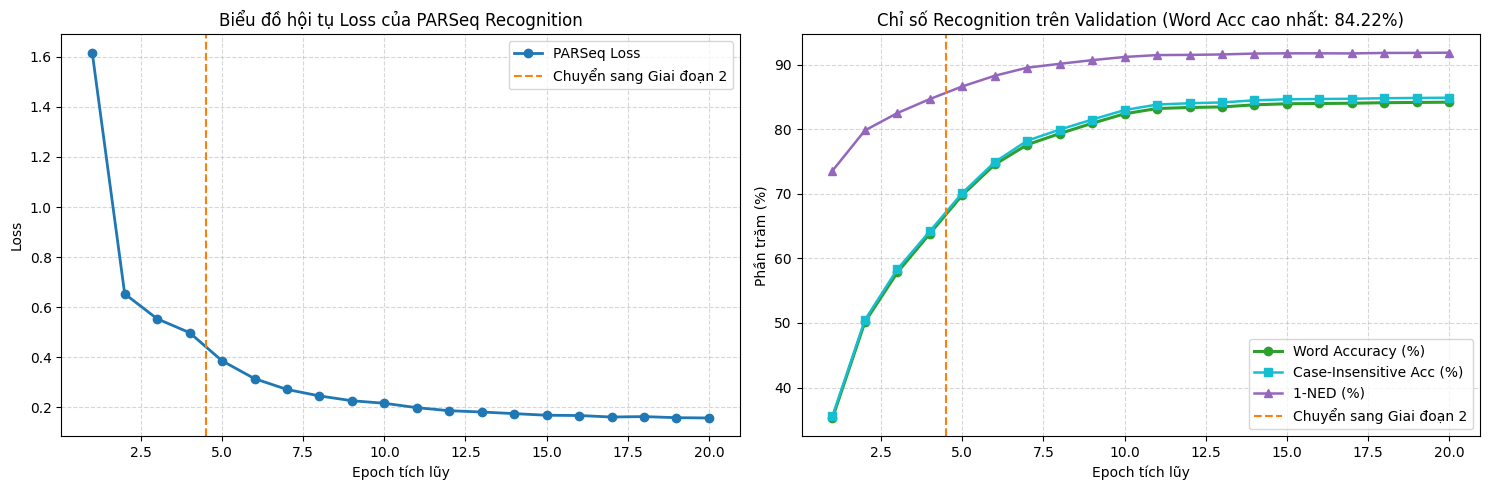

Đã lưu biểu đồ quá trình huấn luyện tại: /kaggle/working/unified_ocr_project/parseq_training_curves.png
Độ dài nhãn tối đa được cấu hình trên mô hình đánh giá: 25
Đang quét tập Test thuộc thuần nguồn VinText Official...
Đã lọc bỏ 797 vùng chữ có chiều cao dưới 12px.
Đã bỏ 2 nhãn dài hơn 25 ký tự.
Giữ lại 6,394 từ VinText có dấu hợp lệ để đánh giá.
Đang chạy benchmark PARSeq trên toàn bộ tập Test VinText có dấu...

KẾT QUẢ BENCHMARK PARSEQ VINTEXT OFFICIAL (6,394 TỪ CÓ DẤU)
Chính xác tuyệt đối (Word Acc): 83.41%
Không phân biệt hoa/thường   : 84.58%
Độ tương đồng ký tự (1-NED)  : 90.88%
Tỷ lệ lỗi ký tự (CER)        : 8.96%


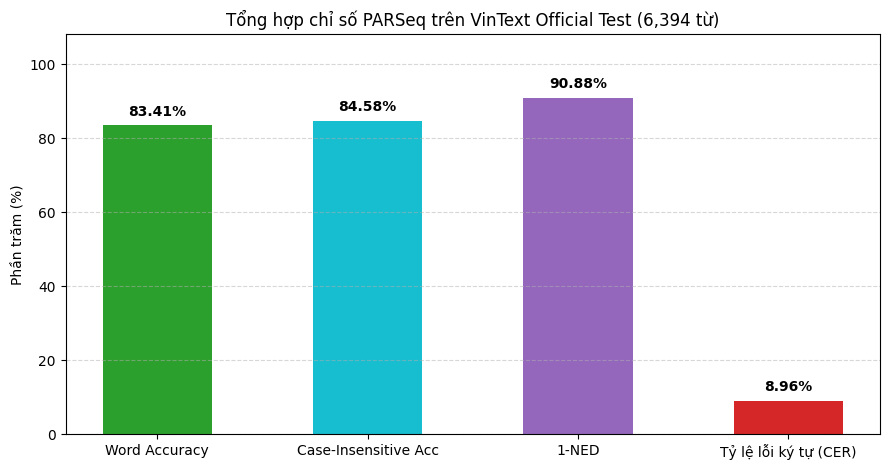

Đã lưu biểu đồ cột chỉ số tại: /kaggle/working/unified_ocr_project/vintext_pure_test_metrics_bar.png


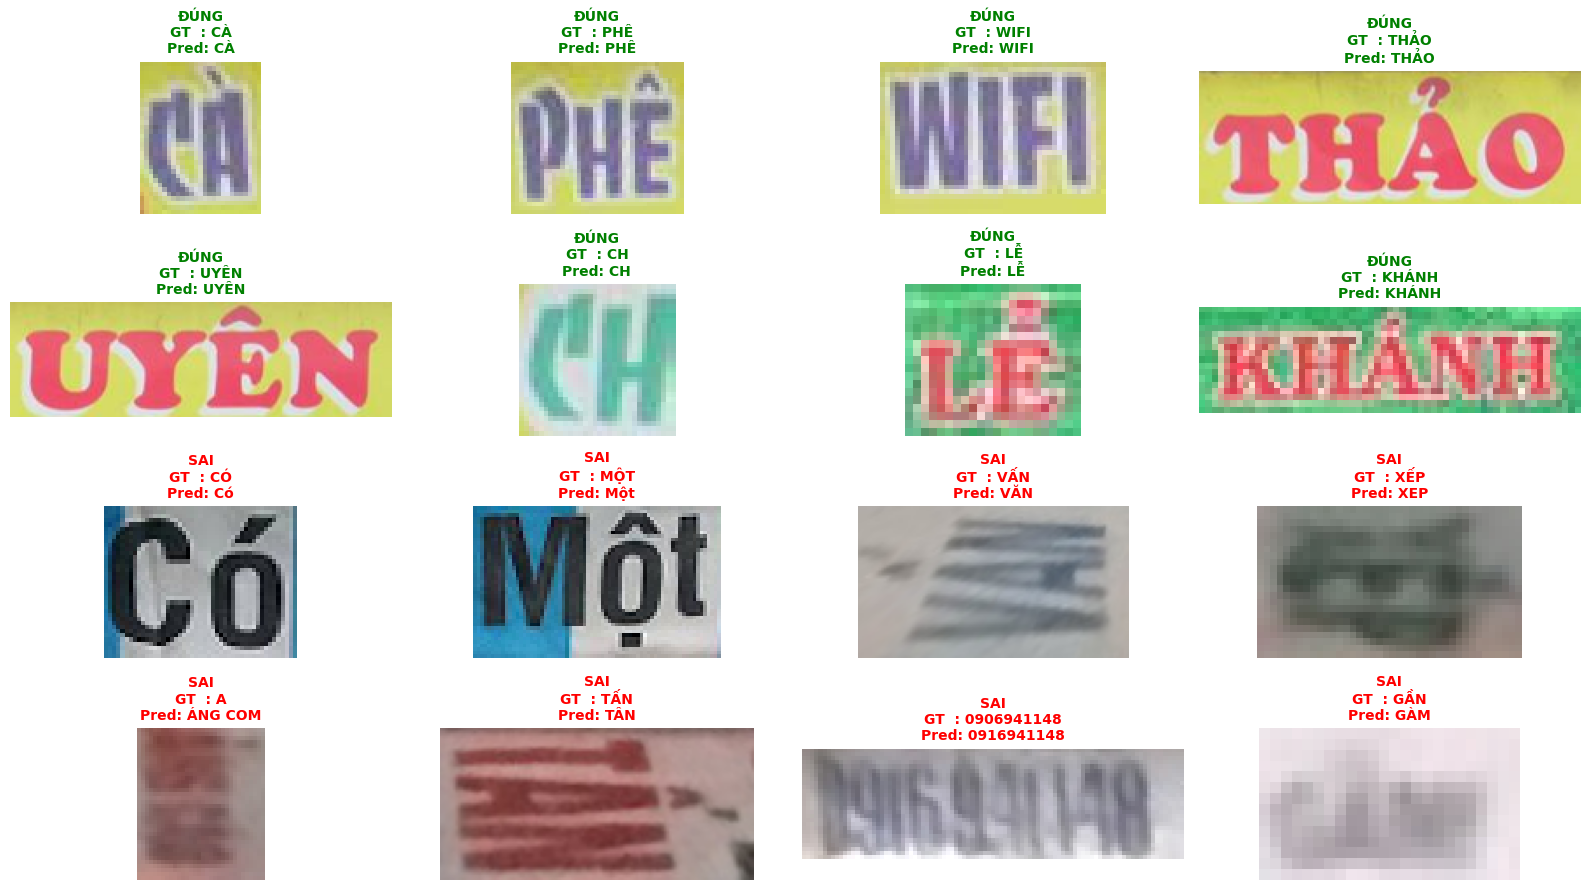

Đã lưu ảnh đối chứng tại: /kaggle/working/unified_ocr_project/vintext_pure_test_benchmark_parseq.png


In [6]:
import unicodedata
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.transforms as T
from PIL import Image

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
work_dir = WORK_DIR if "WORK_DIR" in globals() else Path("/kaggle/working/unified_ocr_project")
export_dir = EXPORT_DIR if "EXPORT_DIR" in globals() else work_dir / "exported_models"
rec_ckpt = Path(BEST_REC_CKPT) if ("BEST_REC_CKPT" in globals() and BEST_REC_CKPT is not None) else (export_dir / "parseq_vietnamese_best.pth")

def plot_parseq_training_history(history: list[dict], save_dir: Path):
    if not history:
        return
    steps = list(range(1, len(history) + 1))
    losses = [h["loss"] for h in history]
    word_accs = [h["word_acc"] for h in history]
    ci_accs = [h["ci_acc"] for h in history]
    one_neds = [h["one_ned"] for h in history]
    stage1_count = sum(1 for h in history if h.get("stage") == 1)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].plot(steps, losses, marker="o", color="#1f77b4", linewidth=2, label="PARSeq Loss")
    if 0 < stage1_count < len(history):
        axes[0].axvline(x=stage1_count + 0.5, color="#ff7f0e", linestyle="--", linewidth=1.5, label="Chuyển sang Giai đoạn 2")
    axes[0].set_title("Biểu đồ hội tụ Loss của PARSeq Recognition")
    axes[0].set_xlabel("Epoch tích lũy")
    axes[0].set_ylabel("Loss")
    axes[0].grid(True, linestyle="--", alpha=0.5)
    axes[0].legend()

    axes[1].plot(steps, word_accs, marker="o", color="#2ca02c", linewidth=2.2, label="Word Accuracy (%)")
    axes[1].plot(steps, ci_accs, marker="s", color="#17becf", linewidth=1.8, label="Case-Insensitive Acc (%)")
    axes[1].plot(steps, one_neds, marker="^", color="#9467bd", linewidth=1.8, label="1-NED (%)")
    if 0 < stage1_count < len(history):
        axes[1].axvline(x=stage1_count + 0.5, color="#ff7f0e", linestyle="--", linewidth=1.5, label="Chuyển sang Giai đoạn 2")
    axes[1].set_title(f"Chỉ số Recognition trên Validation (Word Acc cao nhất: {max(word_accs):.2f}%)")
    axes[1].set_xlabel("Epoch tích lũy")
    axes[1].set_ylabel("Phần trăm (%)")
    axes[1].grid(True, linestyle="--", alpha=0.5)
    axes[1].legend()

    plt.tight_layout()
    curve_path = save_dir / "parseq_training_curves.png"
    plt.savefig(curve_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Đã lưu biểu đồ quá trình huấn luyện tại: {curve_path}")

if "REC_HISTORY" in globals() and REC_HISTORY:
    plot_parseq_training_history(REC_HISTORY, work_dir)

charset_set = set(VIETOCR_CHARS)

def normalize_nfc(text: str) -> str:
    text = unicodedata.normalize("NFC", str(text))
    text = text.replace("\ufeff", "").replace("\u200b", "").replace("\t", " ").replace("\n", " ").replace("\r", " ")
    return " ".join(text.split()).strip()

if not rec_ckpt.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint Recognition: {rec_ckpt}. Hãy chạy xong cell huấn luyện trước."
    )

if "PARSEQ_MODEL" in globals() and PARSEQ_MODEL is not None:
    bench_model = PARSEQ_MODEL.to(device)
else:
    from strhub.models.utils import create_model
    bench_model = create_model(
        "parseq",
        pretrained=False,
        charset_train=VIETOCR_CHARS,
        charset_test=VIETOCR_CHARS,
        max_label_length=MAX_LABEL_LENGTH,
        img_size=(32, 128),
    ).to(device)

state_dict = torch.load(rec_ckpt, map_location=device, weights_only=True)
bench_model.load_state_dict(state_dict, strict=True)
bench_model.eval()

max_label_len = getattr(bench_model, "max_label_length", 25)
print(f"Độ dài nhãn tối đa được cấu hình trên mô hình đánh giá: {max_label_len}")

print("Đang quét tập Test thuộc thuần nguồn VinText Official...")
vintext_pure_test = []
filtered_h = 0
filtered_long = 0

for item in DET_TEST_ITEMS:
    img_p = item["image_path"]
    img_p_lower = img_p.lower()

    if "vintext_official" not in img_p_lower or "icdar" in img_p_lower:
        continue

    for ann in item["annotations"]:
        t = normalize_nfc(ann.get("transcription", ""))
        pts = ann.get("points", [])
        if not t or t == "###" or len(pts) != 4 or not all(ch in charset_set for ch in t):
            continue

        pts_np = np.array(pts, dtype=np.float32).reshape(4, 2)
        h1 = np.linalg.norm(pts_np[0] - pts_np[3])
        h2 = np.linalg.norm(pts_np[1] - pts_np[2])
        box_h = max(h1, h2)

        if box_h < 12.0:
            filtered_h += 1
            continue

        # Không cắt nhãn vì sẽ làm sai ground truth của benchmark.
        if len(t) > max_label_len:
            filtered_long += 1
            continue

        vintext_pure_test.append({
            "img_path": img_p,
            "pts": pts_np,
            "text": t,
        })

print(f"Đã lọc bỏ {filtered_h:,} vùng chữ có chiều cao dưới 12px.")
print(f"Đã bỏ {filtered_long:,} nhãn dài hơn {max_label_len} ký tự.")
print(f"Giữ lại {len(vintext_pure_test):,} từ VinText có dấu hợp lệ để đánh giá.")

def order_points_clockwise(pts: np.ndarray) -> np.ndarray:
    pts = np.asarray(pts, dtype=np.float32).reshape(4, 2)
    center = pts.mean(axis=0)
    angles = np.arctan2(pts[:, 1] - center[1], pts[:, 0] - center[0])
    ordered = pts[np.argsort(angles)]
    if cv2.contourArea(ordered.reshape(-1, 1, 2), oriented=True) < 0:
        ordered = ordered[::-1]
    start = int(np.argmin(ordered.sum(axis=1)))
    return np.roll(ordered, -start, axis=0).astype(np.float32)

def crop_with_padding(img_rgb: np.ndarray, pts: np.ndarray, pad_ratio: float = 0.08) -> np.ndarray:
    rect = order_points_clockwise(pts)
    w = max(4, int(round(max(np.linalg.norm(rect[0] - rect[1]), np.linalg.norm(rect[2] - rect[3])))))
    h = max(4, int(round(max(np.linalg.norm(rect[1] - rect[2]), np.linalg.norm(rect[3] - rect[0])))))
    center = rect.mean(axis=0)
    expanded = rect + (rect - center) * pad_ratio
    dst = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], dtype=np.float32)
    matrix = cv2.getPerspectiveTransform(expanded, dst)
    warped = cv2.warpPerspective(img_rgb, matrix, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
    if warped.shape[0] > warped.shape[1] * 1.5 and warped.shape[0] > 32:
        warped = cv2.rotate(warped, cv2.ROTATE_90_COUNTERCLOCKWISE)
    return warped

parseq_transform = T.Compose([
    T.Resize((32, 128), interpolation=T.InterpolationMode.BICUBIC),
    T.ToTensor(),
    T.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

def prep_parseq_crop(crop_rgb: np.ndarray) -> torch.Tensor:
    return parseq_transform(Image.fromarray(crop_rgb))

def lev_dist(a: str, b: str) -> int:
    if len(a) < len(b):
        return lev_dist(b, a)
    if not b:
        return len(a)
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(cur[j - 1] + 1, prev[j] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

exact, ci_exact, dist_sum, char_sum, word_cnt = 0, 0, 0, 0, 0
ned_scores = []
correct_samples = []
error_samples = []

words_by_img = {}
for w in vintext_pure_test:
    words_by_img.setdefault(w["img_path"], []).append(w)

batch_crops, batch_gts, batch_raw = [], [], []

@torch.inference_mode()
def eval_batch():
    global exact, ci_exact, dist_sum, char_sum, word_cnt
    if not batch_crops:
        return
    b_tensors = torch.stack(batch_crops).to(device, non_blocking=True)
    logits = bench_model(b_tensors)
    probs = logits.softmax(-1)
    preds, _ = bench_model.tokenizer.decode(probs)

    for raw_pred, gt, c_rgb in zip(preds, batch_gts, batch_raw):
        pred = normalize_nfc(raw_pred)
        d = lev_dist(pred, gt)
        l = max(len(pred), len(gt), 1)

        word_cnt += 1
        is_match = (pred == gt)
        exact += int(is_match)
        ci_exact += int(pred.lower() == gt.lower())
        dist_sum += d
        char_sum += max(1, len(gt))
        ned_scores.append(1.0 - (d / l))

        if is_match and len(correct_samples) < 8:
            correct_samples.append({"crop": c_rgb, "gt": gt, "pred": pred, "match": True})
        elif not is_match and len(error_samples) < 8:
            error_samples.append({"crop": c_rgb, "gt": gt, "pred": pred, "match": False})

print("Đang chạy benchmark PARSeq trên toàn bộ tập Test VinText có dấu...")
for img_path, w_list in words_by_img.items():
    bgr = cv2.imread(img_path)
    if bgr is None:
        continue
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    for w in w_list:
        crop = crop_with_padding(rgb, w["pts"], pad_ratio=0.08)
        if crop is None or crop.shape[0] < 4 or crop.shape[1] < 4:
            continue
        batch_crops.append(prep_parseq_crop(crop))
        batch_gts.append(w["text"])
        batch_raw.append(crop)

        if len(batch_crops) >= 128:
            eval_batch()
            batch_crops.clear()
            batch_gts.clear()
            batch_raw.clear()

if batch_crops:
    eval_batch()

word_acc_val = (exact / max(1, word_cnt)) * 100.0
ci_acc_val = (ci_exact / max(1, word_cnt)) * 100.0
one_ned_val = (float(np.mean(ned_scores)) if ned_scores else 0.0) * 100.0
cer_val = (dist_sum / max(1, char_sum)) * 100.0

print("\n" + "=" * 65)
print(f"KẾT QUẢ BENCHMARK PARSEQ VINTEXT OFFICIAL ({word_cnt:,} TỪ CÓ DẤU)")
print("=" * 65)
print(f"Chính xác tuyệt đối (Word Acc): {word_acc_val:.2f}%")
print(f"Không phân biệt hoa/thường   : {ci_acc_val:.2f}%")
print(f"Độ tương đồng ký tự (1-NED)  : {one_ned_val:.2f}%")
print(f"Tỷ lệ lỗi ký tự (CER)        : {cer_val:.2f}%")
print("=" * 65)

fig_bar, ax_bar = plt.subplots(figsize=(9, 4.8))
metric_names = ["Word Accuracy", "Case-Insensitive Acc", "1-NED", "Tỷ lệ lỗi ký tự (CER)"]
metric_values = [word_acc_val, ci_acc_val, one_ned_val, cer_val]
bar_colors = ["#2ca02c", "#17becf", "#9467bd", "#d62728"]

bars = ax_bar.bar(metric_names, metric_values, color=bar_colors, width=0.52)
ax_bar.set_ylim(0, 108)
ax_bar.set_ylabel("Phần trăm (%)")
ax_bar.set_title(f"Tổng hợp chỉ số PARSeq trên VinText Official Test ({word_cnt:,} từ)")
ax_bar.grid(axis="y", linestyle="--", alpha=0.5)

for bar, val in zip(bars, metric_values):
    ax_bar.text(
        bar.get_x() + bar.get_width() / 2.0,
        val + 1.8,
        f"{val:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        weight="bold",
    )

plt.tight_layout()
bar_save_path = work_dir / "vintext_pure_test_metrics_bar.png"
plt.savefig(bar_save_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Đã lưu biểu đồ cột chỉ số tại: {bar_save_path}")

display_samples = correct_samples + error_samples
if display_samples:
    plt.figure(figsize=(16, 9))
    for i, it in enumerate(display_samples):
        ax = plt.subplot(4, 4, i + 1)
        ax.imshow(it["crop"])
        ax.axis("off")
        color = "green" if it["match"] else "red"
        status = "ĐÚNG" if it["match"] else "SAI"
        ax.set_title(f"{status}\nGT  : {it['gt']}\nPred: {it['pred']}", color=color, fontsize=10, weight="bold")

    plt.tight_layout()
    save_path = work_dir / "vintext_pure_test_benchmark_parseq.png"
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Đã lưu ảnh đối chứng tại: {save_path}")